In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

seed = 42

In [3]:
#df = pd.read_excel("sales.xlsx")
df = pd.read_csv("sales.csv")
#df = pd.read_excel("REAL_DATA.xlsx")
df_unknown = pd.read_csv("REAL_DATA.csv")

df = df.rename(columns={"Unnamed: 0": "index"})

print("Labeled Data:", df.shape)
print("Unlabeled Data:", df_unknown.shape)

Labeled Data: (640840, 10)
Unlabeled Data: (71205, 9)


In [4]:
display(df.head())
display(df_unknown.head())

df.info()
df_unknown.info()

,index,store_ID,day_of_week,date,nb_customers_on_day,open,promotion,state_holiday,school_holiday,sales
0,425390,366,4,2013-04-18,517,1,0,0,0,4422
1,291687,394,6,2015-04-11,694,1,0,0,0,8297
2,411278,807,4,2013-08-29,970,1,1,0,0,9729
3,664714,802,2,2013-05-28,473,1,1,0,0,6513
4,540835,726,4,2013-10-10,1068,1,1,0,0,10882


,index,store_ID,day_of_week,date,nb_customers_on_day,open,promotion,state_holiday,school_holiday
0,272371,415,7,01/03/2015,0,0,0,0,0
1,558468,27,7,29/12/2013,0,0,0,0,0
2,76950,404,3,19/03/2014,657,1,1,0,0
3,77556,683,2,29/01/2013,862,1,0,0,0
4,456344,920,3,19/03/2014,591,1,1,0,0


<class 'pandas.DataFrame'>
RangeIndex: 640840 entries, 0 to 640839
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   index                640840 non-null  int64
 1   store_ID             640840 non-null  int64
 2   day_of_week          640840 non-null  int64
 3   date                 640840 non-null  str  
 4   nb_customers_on_day  640840 non-null  int64
 5   open                 640840 non-null  int64
 6   promotion            640840 non-null  int64
 7   state_holiday        640840 non-null  str  
 8   school_holiday       640840 non-null  int64
 9   sales                640840 non-null  int64
dtypes: int64(8), str(2)
memory usage: 48.9 MB
<class 'pandas.DataFrame'>
RangeIndex: 71205 entries, 0 to 71204
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   index                71205 non-null  int64
 1   store_ID           

In [5]:
# Missing values in labeled data
print("Missing values in labeled data:")
print(df.isnull().sum())

# Missing values in unlabeled data
print("\nMissing values in unlabeled data:")
print(df_unknown.isnull().sum())

Missing values in labeled data:
index                  0
store_ID               0
day_of_week            0
date                   0
nb_customers_on_day    0
open                   0
promotion              0
state_holiday          0
school_holiday         0
sales                  0
dtype: int64

Missing values in unlabeled data:
index                  0
store_ID               0
day_of_week            0
date                   0
nb_customers_on_day    0
open                   0
promotion              0
state_holiday          0
school_holiday         0
dtype: int64


In [6]:
# Check Sunday opening and sales

sundays = df[df["day_of_week"] == 7]

print("Total Sundays:", len(sundays))

print("Closed Sundays:",
      (sundays["open"] == 0).sum())

print("Open Sundays:",
      (sundays["open"] == 1).sum())

print("Sundays with Sales = 0:",
      (sundays["sales"] == 0).sum())

print("Sundays with Sales > 0:",
      (sundays["sales"] > 0).sum())

print("All Sundays closed?",
      (sundays["open"] == 0).all())

print("All closed stores have Sales = 0?",
      (df.loc[df["open"] == 0, "sales"] == 0).all())

pd.crosstab(
    sundays["open"],
    sundays["sales"] == 0
)

Total Sundays: 91075
Closed Sundays: 88762
Open Sundays: 2313
Sundays with Sales = 0: 88762
Sundays with Sales > 0: 2313
All Sundays closed? False
All closed stores have Sales = 0? True


sales,False,True
open,,
0,0,88762
1,2313,0


In [7]:
print("Number of stores:", df["store_ID"].nunique())

print("\nObservations per store:")
print(df["store_ID"].value_counts().describe())

Number of stores: 1115

Observations per store:
count    1115.000000
mean      574.744395
std        44.554791
min       436.000000
25%       574.000000
50%       590.000000
75%       601.500000
max       645.000000
Name: count, dtype: float64


In [8]:
print(df["sales"].describe())

print("Zero Sales:", (df["sales"] == 0).sum())
print("Positive Sales:", (df["sales"] > 0).sum())

count    640840.000000
mean       5777.469011
std        3851.338083
min           0.000000
25%        3731.000000
50%        5746.000000
75%        7860.000000
max       41551.000000
Name: sales, dtype: float64
Zero Sales: 108855
Positive Sales: 531985


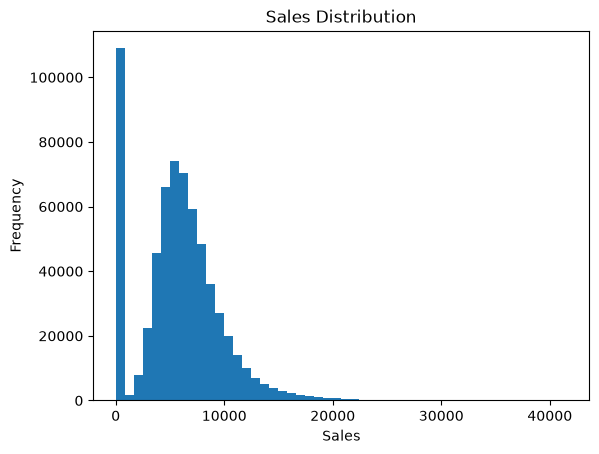

In [9]:
plt.hist(df["sales"], bins=50)
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Sales Distribution")
plt.show()

In [10]:
print("Closed stores with Sales > 0:")
print(((df["open"] == 0) & (df["sales"] > 0)).sum())

print("Open stores with Sales = 0:")
print(((df["open"] == 1) & (df["sales"] == 0)).sum())

Closed stores with Sales > 0:
0
Open stores with Sales = 0:
31


In [11]:
print("Only in labeled data:")
print(set(df.columns) - set(df_unknown.columns))

print("\nOnly in unlabeled data:")
print(set(df_unknown.columns) - set(df.columns))

Only in labeled data:
{'sales'}

Only in unlabeled data:
set()


In [12]:
#Data Cleaning

In [12]:
# Data Cleaning - Date Conversion

df["date"] = pd.to_datetime(
    df["date"], format="%Y-%m-%d"
)

df_unknown["date"] = pd.to_datetime(
    df_unknown["date"], format="%d/%m/%Y"
)

In [13]:
for data in [df, df_unknown]:

    matches = (
        data["date"].dt.dayofweek + 1
        == data["day_of_week"]
    )

    print("Correct dates:", matches.mean())

Correct dates: 1.0
Correct dates: 1.0


C:\Users\andre\AppData\Local\Temp\ipykernel_26472\2154472732.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["date"].dt.dayofweek + 1
C:\Users\andre\AppData\Local\Temp\ipykernel_26472\2154472732.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["date"].dt.dayofweek + 1


In [ ]:
#Data Quality Check

In [14]:
# Check duplicate Store-Date combinations
print("Duplicates in labeled data:")
print(df.duplicated(subset=["store_ID", "date"]).sum())

print("\nDuplicates in unlabeled data:")
print(df_unknown.duplicated(
    subset=["store_ID", "date"]
).sum())

Duplicates in labeled data:
0

Duplicates in unlabeled data:
0


In [ ]:
#DATA FILTERING

In [15]:
df_open = df[df["open"] == 1].copy()

print("Original data:", df.shape)
print("Open stores only:", df_open.shape)

print("Closed stores removed:",
      len(df) - len(df_open))

Original data: (640840, 10)
Open stores only: (532016, 10)
Closed stores removed: 108824


In [16]:

# Basic Feature Engineering - Variant B

for data in [df_open, df_unknown]:

    # Date features
    data["year"] = data["date"].dt.year
    data["month"] = data["date"].dt.month
    data["day_of_month"] = data["date"].dt.day
    data["day_of_year"] = data["date"].dt.dayofyear

    data["week_of_year"] = (
        data["date"].dt.isocalendar().week.astype(int)
    )

    data["is_weekend"] = (
        data["date"].dt.day_of_week >= 5
    ).astype(int)

    # Interaction features
    data["promotion_customers"] = (
        data["promotion"] * data["nb_customers_on_day"]
    )

    data["weekend_customers"] = (
        data["is_weekend"] * data["nb_customers_on_day"]
    )


C:\Users\andre\AppData\Local\Temp\ipykernel_26472\3575391244.py:9: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  data["day_of_year"] = data["date"].dt.dayofyear
C:\Users\andre\AppData\Local\Temp\ipykernel_26472\3575391244.py:9: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  data["day_of_year"] = data["date"].dt.dayofyear


In [17]:

# Categorical Feature Preparation

categorical_features = [
    "store_ID",
    "day_of_week",
    "month",
    "state_holiday"
]

for data in [df_open, df_unknown]:

    for col in categorical_features:
        data[col] = data[col].astype(str)

    data["state_holiday"] = (
        data["state_holiday"]
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )


In [20]:

# Categorical Feature Preparation

categorical_features = [
    "store_ID",
    "day_of_week",
    "month",
    "state_holiday"
]

for data in [df_open, df_unknown]:

    for col in categorical_features:
        data[col] = data[col].astype(str)

    data["state_holiday"] = (
        data["state_holiday"]
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )


In [22]:

# Feature Selection - Initial Feature Set

numerical_features = [
    "nb_customers_on_day",
    "promotion",
    "school_holiday",
    "year",
    "day_of_month",
    "day_of_year",
    "week_of_year",
    "is_weekend",
    "promotion_customers",
    "weekend_customers"
]

features = categorical_features + numerical_features

X = df_open[features].copy()
y = df_open["sales"].copy()

X_unknown = df_unknown[features].copy()

print("X:", X.shape)
print("y:", y.shape)
print("X_unknown:", X_unknown.shape)

display(X.head())



X: (532016, 14)
y: (532016,)
X_unknown: (71205, 14)


,store_ID,day_of_week,month,state_holiday,nb_customers_on_day,promotion,school_holiday,year,day_of_month,day_of_year,week_of_year,is_weekend,promotion_customers,weekend_customers
0,366,4,4,0,517,0,0,2013,18,108,16,0,0,0
1,394,6,4,0,694,0,0,2015,11,101,15,1,0,694
2,807,4,8,0,970,1,0,2013,29,241,35,0,970,0
3,802,2,5,0,473,1,0,2013,28,148,22,0,473,0
4,726,4,10,0,1068,1,0,2013,10,283,41,0,1068,0


In [23]:

# Train/Test Split - Variant B

from sklearn.model_selection import train_test_split

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=seed,
    shuffle=True,
    stratify=df_open["store_ID"]
)

print("Development X:", X_dev.shape)
print("Test X:", X_test.shape)

print("Development y:", y_dev.shape)
print("Test y:", y_test.shape)


Development X: (478814, 14)
Test X: (53202, 14)
Development y: (478814,)
Test y: (53202,)


In [24]:

# 5-Fold Cross-Validation Setup

from sklearn.model_selection import KFold

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=seed
)

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_dev), start=1
):
    print(
        f"Fold {fold}: "
        f"Training = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )


Fold 1: Training = 383051, Validation = 95763
Fold 2: Training = 383051, Validation = 95763
Fold 3: Training = 383051, Validation = 95763
Fold 4: Training = 383051, Validation = 95763
Fold 5: Training = 383052, Validation = 95762


In [25]:
# Install additional regression algorithms
%pip install catboost lightgbm

  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/101.7 MB 4.0 MB/s eta 0:00:25
    --------------------------------------- 1.3/101.7 MB 4.0 MB/s eta 0:00:26
    --------------------------------------- 2.1/101.7 MB 3.8 MB/s eta 0:00:27
   - -------------------------------------- 3.1/101.7 MB 3.9 MB/s eta 0:00:26
   - -------------------------------------- 4.2/101.7 MB 4.2 MB/s eta 0:00:24
   -- ------------------------------------- 5.2/101.7 MB 4.5 MB/s eta 0:00:22
   -- ------------------------------------- 6.3/101.7 MB 4.4 MB/s eta 0:00:22
   -- ------------------------------------- 7.1/101.7 MB 4.4 MB/s eta 0:00:22
   --- ------------------------------------ 8.1/101.7 MB 4.4 MB/s eta 0:00:22
   --- ------------------------------------ 9.2/101.7 MB 4.4 MB/s eta 0:00:21
   --- ------------------------------------ 10.0/101.7 MB 4.5 MB/s eta 0:00:21
   --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
# Algorithm Selection - Imports and CV Preparation

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

# Use the same 5 folds for all algorithms
folds = list(kf.split(X_dev))

# Store results and out-of-fold predictions
cv_results = []
oof_predictions = {}

In [27]:

# Algorithm 1 - Individual Linear Regression (5-Fold CV)

X_dev_linear = X_dev.copy()

# Numeric preparation for Linear Regression
for col in ["store_ID", "day_of_week", "month"]:
    X_dev_linear[col] = pd.to_numeric(X_dev_linear[col])

X_dev_linear["state_holiday"] = (
    X_dev_linear["state_holiday"] != "0"
).astype(int)

local_features = [
    col for col in X_dev_linear.columns
    if col != "store_ID"
]

oof_local = np.full(len(X_dev_linear), np.nan)

for fold, (train_idx, val_idx) in enumerate(folds, start=1):

    X_train_fold = X_dev_linear.iloc[train_idx]
    X_val_fold = X_dev_linear.iloc[val_idx]

    y_train_fold = y_dev.iloc[train_idx]
    y_val_fold = y_dev.iloc[val_idx]

    # Global fallback model
    global_model = LinearRegression()
    global_model.fit(X_train_fold, y_train_fold)

    pred_train = pd.Series(
        global_model.predict(X_train_fold),
        index=X_train_fold.index
    )

    pred_val = pd.Series(
        global_model.predict(X_val_fold),
        index=X_val_fold.index
    )

    # Individual models per store
    for store_id, store_data in X_train_fold.groupby("store_ID"):

        if len(store_data) < 50:
            continue

        local_model = LinearRegression()

        local_model.fit(
            store_data[local_features],
            y_train_fold.loc[store_data.index]
        )

        # Training predictions
        pred_train.loc[store_data.index] = local_model.predict(
            store_data[local_features]
        )

        # Validation predictions
        mask = X_val_fold["store_ID"] == store_id

        if mask.any():
            pred_val.loc[mask] = local_model.predict(
                X_val_fold.loc[mask, local_features]
            )

    # Evaluate fold
    train_r2 = r2_score(y_train_fold, pred_train)
    val_r2 = r2_score(y_val_fold, pred_val)

    # Save out-of-fold predictions
    oof_local[val_idx] = pred_val.to_numpy()

    cv_results.append({
        "Model": "Individual Linear Regression",
        "Fold": fold,
        "Training R²": train_r2,
        "Validation R²": val_r2
    })

    print(
        f"Fold {fold}: "
        f"Training R² = {train_r2:.6f}, "
        f"Validation R² = {val_r2:.6f}"
    )

oof_predictions["Individual Linear Regression"] = pd.Series(
    oof_local, index=X_dev.index
)


Fold 1: Training R² = 0.979263, Validation R² = 0.976667
Fold 2: Training R² = 0.979042, Validation R² = 0.977959
Fold 3: Training R² = 0.979420, Validation R² = 0.976243
Fold 4: Training R² = 0.979247, Validation R² = 0.977003
Fold 5: Training R² = 0.979612, Validation R² = 0.975498


In [28]:

# Algorithm 2 - CatBoost Regressor (5-Fold CV)

oof_catboost = np.full(len(X_dev), np.nan)

for fold, (train_idx, val_idx) in enumerate(folds, start=1):

    X_train_fold = X_dev.iloc[train_idx]
    X_val_fold = X_dev.iloc[val_idx]

    y_train_fold = y_dev.iloc[train_idx]
    y_val_fold = y_dev.iloc[val_idx]

    # Create model
    cat_model = CatBoostRegressor(
        iterations=300,
        depth=8,
        learning_rate=0.08,
        loss_function="RMSE",
        random_seed=seed,
        verbose=False
    )

    # Train model
    cat_model.fit(
        X_train_fold,
        y_train_fold,
        cat_features=categorical_features
    )

    # Predictions
    pred_train = cat_model.predict(X_train_fold)
    pred_val = cat_model.predict(X_val_fold)

    # Evaluate fold
    train_r2 = r2_score(y_train_fold, pred_train)
    val_r2 = r2_score(y_val_fold, pred_val)

    # Save out-of-fold predictions
    oof_catboost[val_idx] = pred_val

    cv_results.append({
        "Model": "CatBoost",
        "Fold": fold,
        "Training R²": train_r2,
        "Validation R²": val_r2
    })

    print(
        f"Fold {fold}: "
        f"Training R² = {train_r2:.6f}, "
        f"Validation R² = {val_r2:.6f}"
    )

oof_predictions["CatBoost"] = pd.Series(
    oof_catboost, index=X_dev.index
)


Fold 1: Training R² = 0.969472, Validation R² = 0.968140
Fold 2: Training R² = 0.968741, Validation R² = 0.969725
Fold 3: Training R² = 0.969954, Validation R² = 0.968485
Fold 4: Training R² = 0.969787, Validation R² = 0.968865
Fold 5: Training R² = 0.970078, Validation R² = 0.967518


In [29]:

# Algorithm 3 - LightGBM Regressor (5-Fold CV)

X_dev_lgbm = X_dev.copy()

for col in categorical_features:
    X_dev_lgbm[col] = X_dev_lgbm[col].astype("category")

oof_lgbm = np.full(len(X_dev_lgbm), np.nan)

for fold, (train_idx, val_idx) in enumerate(folds, start=1):

    X_train_fold = X_dev_lgbm.iloc[train_idx]
    X_val_fold = X_dev_lgbm.iloc[val_idx]

    y_train_fold = y_dev.iloc[train_idx]
    y_val_fold = y_dev.iloc[val_idx]

    # Create model
    lgbm_model = LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=63,
        random_state=seed,
        n_jobs=-1,
        verbosity=-1
    )

    # Train model
    lgbm_model.fit(
        X_train_fold,
        y_train_fold,
        categorical_feature=categorical_features
    )

    # Predictions
    pred_train = lgbm_model.predict(X_train_fold)
    pred_val = lgbm_model.predict(X_val_fold)

    # Evaluate fold
    train_r2 = r2_score(y_train_fold, pred_train)
    val_r2 = r2_score(y_val_fold, pred_val)

    # Save out-of-fold predictions
    oof_lgbm[val_idx] = pred_val

    cv_results.append({
        "Model": "LightGBM",
        "Fold": fold,
        "Training R²": train_r2,
        "Validation R²": val_r2
    })

    print(
        f"Fold {fold}: "
        f"Training R² = {train_r2:.6f}, "
        f"Validation R² = {val_r2:.6f}"
    )

oof_predictions["LightGBM"] = pd.Series(
    oof_lgbm, index=X_dev.index
)


Fold 1: Training R² = 0.983600, Validation R² = 0.979380
Fold 2: Training R² = 0.983233, Validation R² = 0.980444
Fold 3: Training R² = 0.984777, Validation R² = 0.980002
Fold 4: Training R² = 0.983456, Validation R² = 0.979533
Fold 5: Training R² = 0.984876, Validation R² = 0.979501


In [30]:

# Algorithm Comparison - 5-Fold CV Results

cv_df = pd.DataFrame(cv_results)

# Average scores across folds
comparison = cv_df.groupby("Model").agg(
    Train_R2=("Training R²", "mean"),
    Validation_R2=("Validation R²", "mean"),
    Validation_Std=("Validation R²", "std")
).reset_index()

# Combined out-of-fold R²
comparison["OOF_R2"] = comparison["Model"].map({
    name: r2_score(y_dev, predictions)
    for name, predictions in oof_predictions.items()
})

# Difference between training and validation
comparison["R2_Gap"] = (
    comparison["Train_R2"]
    - comparison["Validation_R2"]
)

# Rank models by mean validation R²
comparison = comparison.sort_values(
    "Validation_R2",
    ascending=False
)

display(comparison.round(6))

# Individual fold results
display(cv_df.round(6))


,Model,Train_R2,Validation_R2,Validation_Std,OOF_R2,R2_Gap
2,LightGBM,0.983988,0.979772,0.000444,0.979772,0.004216
1,Individual Linear Regression,0.979317,0.976674,0.000912,0.976674,0.002643
0,CatBoost,0.969606,0.968547,0.000824,0.968547,0.001060


,Model,Fold,Training R²,Validation R²
0,Individual Linear Regression,1,0.979263,0.976667
1,Individual Linear Regression,2,0.979042,0.977959
2,Individual Linear Regression,3,0.979420,0.976243
3,Individual Linear Regression,4,0.979247,0.977003
4,Individual Linear Regression,5,0.979612,0.975498
5,CatBoost,1,0.969472,0.968140
6,CatBoost,2,0.968741,0.969725
7,CatBoost,3,0.969954,0.968485
8,CatBoost,4,0.969787,0.968865
9,CatBoost,5,0.970078,0.967518


In [32]:

# Feature Selection - LightGBM

interaction_features = [
    "promotion_customers",
    "weekend_customers"
]

extra_calendar_features = [
    "day_of_year",
    "week_of_year"
]

feature_sets = {
    "All Features": list(X_dev_lgbm.columns),

    "No Interactions": [
        col for col in X_dev_lgbm.columns
        if col not in interaction_features
    ],

    "No Extra Calendar": [
        col for col in X_dev_lgbm.columns
        if col not in extra_calendar_features
    ],

    "No Interactions + Calendar": [
        col for col in X_dev_lgbm.columns
        if col not in interaction_features + extra_calendar_features
    ]
}

feature_results = []

for variant_name, selected_features in feature_sets.items():

    fold_scores = []
    fold_train_scores = []

    for train_idx, val_idx in folds:

        X_train_fold = X_dev_lgbm.iloc[train_idx][selected_features]
        X_val_fold = X_dev_lgbm.iloc[val_idx][selected_features]

        y_train_fold = y_dev.iloc[train_idx]
        y_val_fold = y_dev.iloc[val_idx]

        model_feature = LGBMRegressor(
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=63,
            random_state=seed,
            n_jobs=-1,
            verbosity=-1
        )

        model_feature.fit(
            X_train_fold,
            y_train_fold,
            categorical_feature=[
                col for col in categorical_features
                if col in selected_features
            ]
        )

        predictions = model_feature.predict(X_val_fold)
        train_predictions = model_feature.predict(X_train_fold)

        fold_train_scores.append(
            r2_score(y_train_fold, train_predictions)
        )


        fold_scores.append(
            r2_score(y_val_fold, predictions)
        )

    feature_results.append({
        "Feature Set": variant_name,
        "Number of Features": len(selected_features),
        "Mean Training R²": np.mean(fold_train_scores),
        "Mean Validation R²": np.mean(fold_scores),
        "Validation Std": np.std(fold_scores, ddof=1),
        "R² Gap": np.mean(fold_train_scores) - np.mean(fold_scores)
    })

feature_comparison = pd.DataFrame(feature_results)

feature_comparison = feature_comparison.sort_values(
    "Mean Validation R²",
    ascending=False
)

display(feature_comparison.round(6))


,Feature Set,Number of Features,Mean Training R²,Mean Validation R²,Validation Std,R² Gap
0,All Features,14,0.983988,0.979772,0.000444,0.004216
1,No Interactions,12,0.983944,0.979761,0.000488,0.004183
2,No Extra Calendar,12,0.983780,0.979555,0.000437,0.004225
3,No Interactions + Calendar,10,0.983689,0.979554,0.000514,0.004136


In [ ]:
#HYPERPARAMETER LIGHTGBM

In [33]:
LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    random_state=seed,
    n_jobs=-1,
    verbosity=-1
)

,num_leaves,63
,learning_rate,0.05
,n_estimators,300
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [34]:

# Hyperparameter Tuning - LightGBM (5-Fold CV)

best_features = feature_sets["All Features"]

# Different hyperparameter configurations
param_sets = [
    {
        "name": "Baseline",
        "n_estimators": 300,
        "learning_rate": 0.05,
        "num_leaves": 63,
        "min_child_samples": 20,
        "reg_lambda": 0.0
    },
    {
        "name": "Fewer Leaves",
        "n_estimators": 300,
        "learning_rate": 0.05,
        "num_leaves": 31,
        "min_child_samples": 20,
        "reg_lambda": 0.0
    },
    {
        "name": "More Leaves",
        "n_estimators": 300,
        "learning_rate": 0.05,
        "num_leaves": 127,
        "min_child_samples": 20,
        "reg_lambda": 0.0
    },
    {
        "name": "More Trees",
        "n_estimators": 500,
        "learning_rate": 0.05,
        "num_leaves": 63,
        "min_child_samples": 20,
        "reg_lambda": 0.0
    },
    {
        "name": "Regularized",
        "n_estimators": 500,
        "learning_rate": 0.03,
        "num_leaves": 31,
        "min_child_samples": 50,
        "reg_lambda": 1.0
    }
]

tuning_results = []
tuning_oof_predictions = {}

for params in param_sets:

    train_scores = []
    val_scores = []

    oof = np.full(len(X_dev_lgbm), np.nan)

    for fold, (train_idx, val_idx) in enumerate(folds, start=1):

        # Training and validation data
        X_train_fold = X_dev_lgbm.iloc[train_idx][best_features]
        X_val_fold = X_dev_lgbm.iloc[val_idx][best_features]

        y_train_fold = y_dev.iloc[train_idx]
        y_val_fold = y_dev.iloc[val_idx]

        # Create model
        model_tuning = LGBMRegressor(
            n_estimators=params["n_estimators"],
            learning_rate=params["learning_rate"],
            num_leaves=params["num_leaves"],
            min_child_samples=params["min_child_samples"],
            reg_lambda=params["reg_lambda"],
            random_state=seed,
            n_jobs=-1,
            verbosity=-1
        )

        # Train model
        model_tuning.fit(
            X_train_fold,
            y_train_fold,
            categorical_feature=categorical_features
        )

        # Predictions
        pred_train = model_tuning.predict(X_train_fold)
        pred_val = model_tuning.predict(X_val_fold)

        # R² scores
        train_scores.append(
            r2_score(y_train_fold, pred_train)
        )

        val_scores.append(
            r2_score(y_val_fold, pred_val)
        )

        # Out-of-fold predictions
        oof[val_idx] = pred_val

    # Save OOF predictions
    tuning_oof_predictions[params["name"]] = oof.copy()

    # Save results
    tuning_results.append({
        "Configuration": params["name"],
        "Train_R2": np.mean(train_scores),
        "Validation_R2": np.mean(val_scores),
        "Validation_Std": np.std(val_scores, ddof=1),
        "OOF_R2": r2_score(y_dev, oof),
        "R2_Gap": np.mean(train_scores) - np.mean(val_scores)
    })

    print(
        params["name"],
        "- Validation R²:",
        round(np.mean(val_scores), 6)
    )

# Comparison table
tuning_comparison = pd.DataFrame(tuning_results)

tuning_comparison = tuning_comparison.sort_values(
    "Validation_R2",
    ascending=False
)

display(tuning_comparison.round(6))


Baseline - Validation R²: 0.979772
Fewer Leaves - Validation R²: 0.977682
More Leaves - Validation R²: 0.98076
More Trees - Validation R²: 0.98089
Regularized - Validation R²: 0.977662


,Configuration,Train_R2,Validation_R2,Validation_Std,OOF_R2,R2_Gap
3,More Trees,0.985819,0.980890,0.000365,0.980890,0.004929
2,More Leaves,0.986482,0.980760,0.000558,0.980761,0.005721
0,Baseline,0.983988,0.979772,0.000444,0.979772,0.004216
1,Fewer Leaves,0.980656,0.977682,0.000534,0.977683,0.002973
4,Regularized,0.980519,0.977662,0.000665,0.977662,0.002857


In [35]:
# Best Hyperparameter Configuration

best_config_name = tuning_comparison.iloc[0]["Configuration"]

best_params = next(
    params for params in param_sets
    if params["name"] == best_config_name
)

print("Best configuration:", best_config_name)
print("Best hyperparameters:", best_params)
print(
    "Best CV Validation R²:",
    round(tuning_comparison.iloc[0]["Validation_R2"], 6)
)

Best configuration: More Trees
Best hyperparameters: {'name': 'More Trees', 'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 63, 'min_child_samples': 20, 'reg_lambda': 0.0}
Best CV Validation R²: 0.98089


In [36]:

# Final Test Evaluation - Variant B

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Prepare test data
X_test_lgbm = X_test[best_features].copy()

# Use the same categorical values as in development data
for col in categorical_features:
    X_test_lgbm[col] = pd.Categorical(
        X_test_lgbm[col],
        categories=X_dev_lgbm[col].cat.categories
    )

# Create final evaluation model
final_eval_model = LGBMRegressor(
    n_estimators=best_params["n_estimators"],
    learning_rate=best_params["learning_rate"],
    num_leaves=best_params["num_leaves"],
    min_child_samples=best_params["min_child_samples"],
    reg_lambda=best_params["reg_lambda"],
    random_state=seed,
    n_jobs=-1,
    verbosity=-1
)

# Train on all 90% development data
final_eval_model.fit(
    X_dev_lgbm[best_features],
    y_dev,
    categorical_feature=categorical_features
)

# Predict development and test data
pred_dev = final_eval_model.predict(
    X_dev_lgbm[best_features]
)

pred_test = final_eval_model.predict(
    X_test_lgbm
)

# Calculate scores
r2_dev = r2_score(y_dev, pred_dev)
r2_test = r2_score(y_test, pred_test)

rmse_test = np.sqrt(
    mean_squared_error(y_test, pred_test)
)

mae_test = mean_absolute_error(y_test, pred_test)

print("Development Training R²:", round(r2_dev, 6))
print("5-Fold CV R²:", round(tuning_comparison.iloc[0]["Validation_R2"], 6))
print("Independent Test R²:", round(r2_test, 6))
print("Training / Test R² Gap:", round(r2_dev - r2_test, 6))
print("Test RMSE:", round(rmse_test, 2))
print("Test MAE:", round(mae_test, 2))


Development Training R²: 0.985436
5-Fold CV R²: 0.98089
Independent Test R²: 0.981549
Training / Test R² Gap: 0.003886
Test RMSE: 420.0
Test MAE: 280.52


In [37]:

# Final Training - Variant B

# All labeled open observations
X_final = X[best_features].copy()
y_final = y.copy()

# Unknown observations
X_unknown_final = X_unknown[best_features].copy()

# Prepare categorical features
for col in categorical_features:

    categories = X_final[col].astype(str).unique()

    X_final[col] = pd.Categorical(
        X_final[col].astype(str),
        categories=categories
    )

    X_unknown_final[col] = pd.Categorical(
        X_unknown_final[col].astype(str),
        categories=categories
    )

# Final LightGBM model
final_model_B = LGBMRegressor(
    n_estimators=best_params["n_estimators"],
    learning_rate=best_params["learning_rate"],
    num_leaves=best_params["num_leaves"],
    min_child_samples=best_params["min_child_samples"],
    reg_lambda=best_params["reg_lambda"],
    random_state=seed,
    n_jobs=-1,
    verbosity=-1
)

# Train on all open observations
final_model_B.fit(
    X_final,
    y_final,
    categorical_feature=categorical_features
)

print("Final training completed")
print("Training observations:", len(X_final))
print("Features:", len(best_features))


Final training completed
Training observations: 532016
Features: 14


In [38]:

# Final Predictions - Variant B

# Keep original row order
final_predictions_B = pd.Series(
    0.0,
    index=df_unknown.index,
    name="sales"
)

# Identify open stores
unknown_open = df_unknown["open"] == 1

# Predict sales for open stores
final_predictions_B.loc[unknown_open] = (
    final_model_B.predict(
        X_unknown_final.loc[unknown_open]
    )
)

# Check results
print("Total predictions:", len(final_predictions_B))
print("Missing predictions:", final_predictions_B.isna().sum())
print("Closed stores:", (~unknown_open).sum())
print(
    "Negative predictions:",
    (final_predictions_B < 0).sum()
)

display(final_predictions_B.head(10))


Total predictions: 71205
Missing predictions: 0
Closed stores: 12100
Negative predictions: 0


0       0.000000
1       0.000000
2    5510.546168
3    8464.466359
4    5878.997282
5    4032.833891
6    3074.568369
7    7752.424914
8       0.000000
9    7872.365124
Name: sales, dtype: float64

In [39]:

# Submission File - Variant B

if "index" in df_unknown.columns:
    submission_B = pd.DataFrame({
        "index": df_unknown["index"].to_numpy(),
        "sales": final_predictions_B.to_numpy()
    })

elif "Unnamed: 0" in df_unknown.columns:
    submission_B = pd.DataFrame({
        "index": df_unknown["Unnamed: 0"].to_numpy(),
        "sales": final_predictions_B.to_numpy()
    })

else:
    submission_B = pd.DataFrame({
        "sales": final_predictions_B.to_numpy()
    })

submission_B.to_csv(
    "submission_varianteB.csv",
    index=False
)

print("Submission shape:", submission_B.shape)
display(submission_B.head(10))


Submission shape: (71205, 2)


,index,sales
0,272371,0.000000
1,558468,0.000000
2,76950,5510.546168
3,77556,8464.466359
4,456344,5878.997282
5,436466,4032.833891
6,646251,3074.568369
7,650464,7752.424914
8,162710,0.000000
9,100327,7872.365124
